In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns

In [36]:
df = pd.read_csv("C:\\Users\\user\\OneDrive\\Desktop\\BTCUSD-2y.csv", parse_dates=["Date"], index_col="Date")
print(df)

           Timestamp     Open     High      Low    Close    Volume
Date                                                              
2023-04-02  00:00:00  28433.1  28503.4  27843.4  28149.1  0.105614
2023-04-03  00:00:00  28149.1  28469.0  27190.2  27768.0  0.579852
2023-04-04  00:00:00  27767.9  28402.1  27633.2  28135.8  0.803473
2023-04-05  00:00:00  28134.2  28748.1  27776.1  28143.2  1.077828
2023-04-06  00:00:00  28142.5  28157.1  27684.7  28007.6  0.283230
...              ...      ...      ...      ...      ...       ...
2025-03-28  00:00:00  87174.5  87454.4  83503.7  84316.7  0.436920
2025-03-29  00:00:00  84320.9  84519.0  81557.7  82551.7  0.192708
2025-03-30  00:00:00  82559.3  83443.8  81538.2  82338.9  0.159753
2025-03-31  00:00:00  82352.4  83899.9  81260.5  82518.0  0.237001
2025-04-01  00:00:00  82516.9  85496.4  82388.9  85152.6  0.205276

[725 rows x 6 columns]


In [37]:
print(df.head())

           Timestamp     Open     High      Low    Close    Volume
Date                                                              
2023-04-02  00:00:00  28433.1  28503.4  27843.4  28149.1  0.105614
2023-04-03  00:00:00  28149.1  28469.0  27190.2  27768.0  0.579852
2023-04-04  00:00:00  27767.9  28402.1  27633.2  28135.8  0.803473
2023-04-05  00:00:00  28134.2  28748.1  27776.1  28143.2  1.077828
2023-04-06  00:00:00  28142.5  28157.1  27684.7  28007.6  0.283230


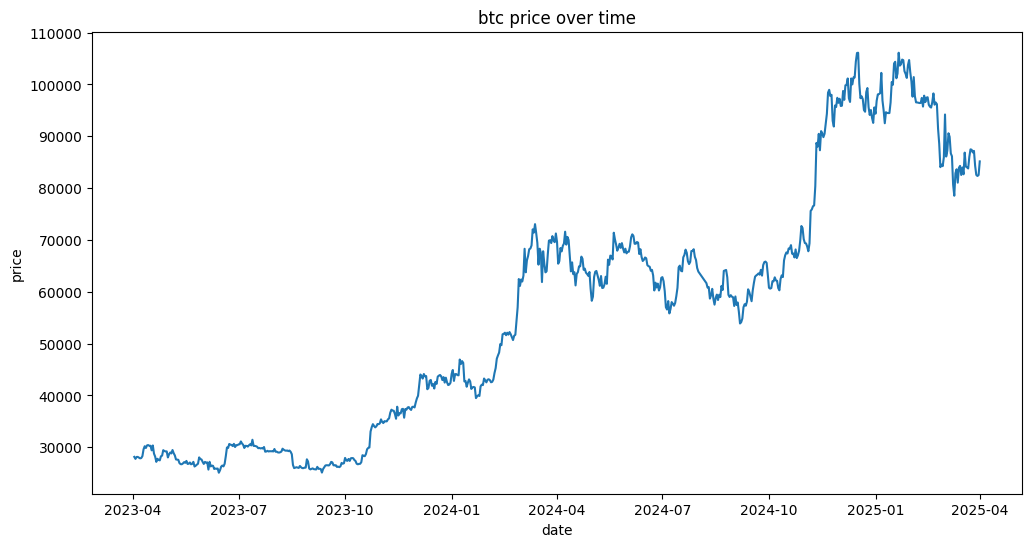

In [38]:
plt.figure(figsize=(12,6))
plt.plot(df['Close'])
plt.title('btc price over time')
plt.xlabel('date')
plt.ylabel('price')
plt.show()

In [39]:
df = df.sort_index()

In [40]:
df["log_return"] = np.log(df["Close"] / df["Close"].shift(1))

In [41]:
df.dropna( inplace = True)

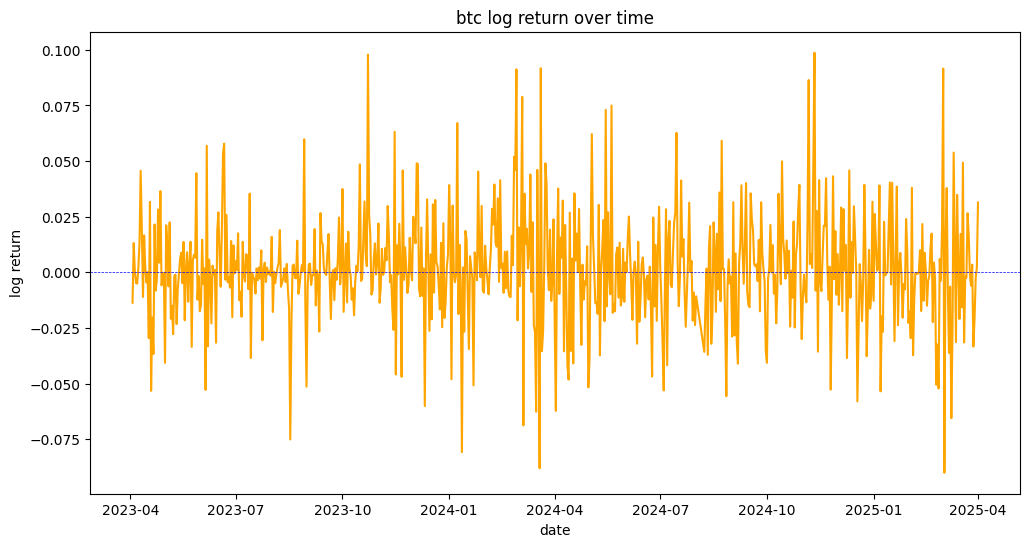

In [42]:
plt.figure(figsize=(12,6))
plt.plot(df['log_return'], label= "log_return", color="orange")
plt.axhline(0, color="blue", linewidth=0.5, linestyle="dashed")
plt.title('btc log return over time')
plt.xlabel('date')
plt.ylabel('log return')
plt.show()

In [43]:
from statsmodels.tsa.stattools import adfuller

In [44]:
result = adfuller(df['log_return'])
print(f'adf statistics: {result[0]}')
print(f'p-value: {result[1]}')

if result[1]>0.05:
    print("data is non stationary, diffrencing is required")
else:
    print("data is stationary")

adf statistics: -28.548314357777148
p-value: 0.0
data is stationary


In [45]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf


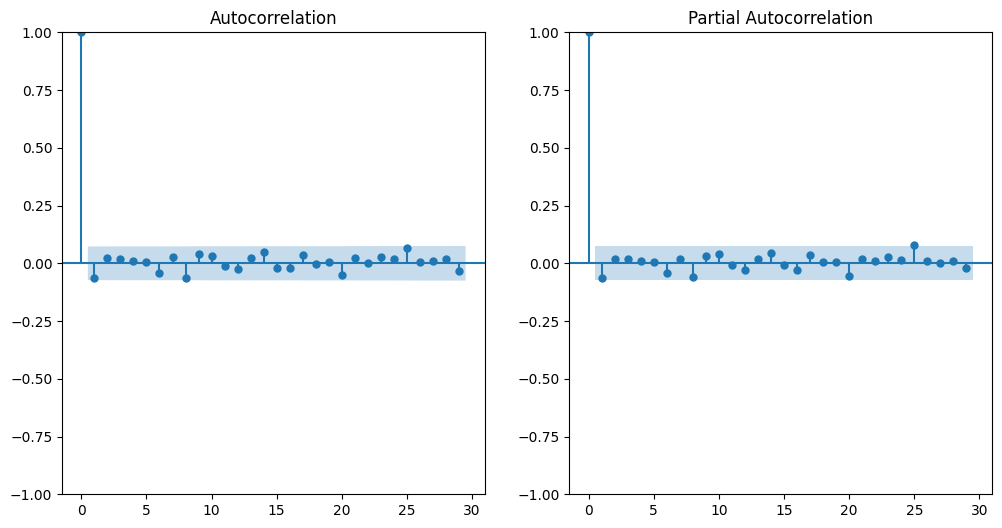

In [46]:
plt.figure(figsize=(12,6))
plt.subplot(121)
plot_acf(df['log_return'].dropna(), ax=plt.gca())

plt.subplot(122)
plot_pacf(df['log_return'].dropna(), ax=plt.gca())
plt.show()

choosing 1 for both p and q

In [47]:
import pmdarima as pm
model = pm.auto_arima(df['log_return'], seasonal=False, stepwise=True, trace=True)

print(model.summary())

C:\Users\user\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\user\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\user\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\user\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\user\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was ren

Performing stepwise search to minimize aic
 ARIMA(2,0,2)(0,0,0)[0]             : AIC=-3302.205, Time=0.14 sec
 ARIMA(0,0,0)(0,0,0)[0]             : AIC=-3306.702, Time=0.03 sec
 ARIMA(1,0,0)(0,0,0)[0]             : AIC=-3307.128, Time=0.08 sec


C:\Users\user\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\user\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\user\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


 ARIMA(0,0,1)(0,0,0)[0]             : AIC=-3307.000, Time=0.33 sec
 ARIMA(2,0,0)(0,0,0)[0]             : AIC=-3305.547, Time=0.07 sec
 ARIMA(1,0,1)(0,0,0)[0]             : AIC=-3305.356, Time=0.10 sec


C:\Users\user\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\user\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\user\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\user\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


 ARIMA(2,0,1)(0,0,0)[0]             : AIC=-3303.572, Time=0.10 sec
 ARIMA(1,0,0)(0,0,0)[0] intercept   : AIC=-3308.275, Time=0.04 sec
 ARIMA(0,0,0)(0,0,0)[0] intercept   : AIC=-3307.498, Time=0.05 sec
 ARIMA(2,0,0)(0,0,0)[0] intercept   : AIC=-3306.562, Time=0.14 sec
 ARIMA(1,0,1)(0,0,0)[0] intercept   : AIC=-3306.447, Time=0.19 sec


C:\Users\user\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\user\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


 ARIMA(0,0,1)(0,0,0)[0] intercept   : AIC=-3308.153, Time=0.09 sec


C:\Users\user\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


 ARIMA(2,0,1)(0,0,0)[0] intercept   : AIC=-3304.551, Time=0.63 sec

Best model:  ARIMA(1,0,0)(0,0,0)[0] intercept
Total fit time: 1.996 seconds
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  724
Model:               SARIMAX(1, 0, 0)   Log Likelihood                1657.137
Date:                Thu, 17 Apr 2025   AIC                          -3308.275
Time:                        13:33:22   BIC                          -3294.520
Sample:                             0   HQIC                         -3302.966
                                - 724                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept      0.0016      0.001      1.754      0.079      -0.000

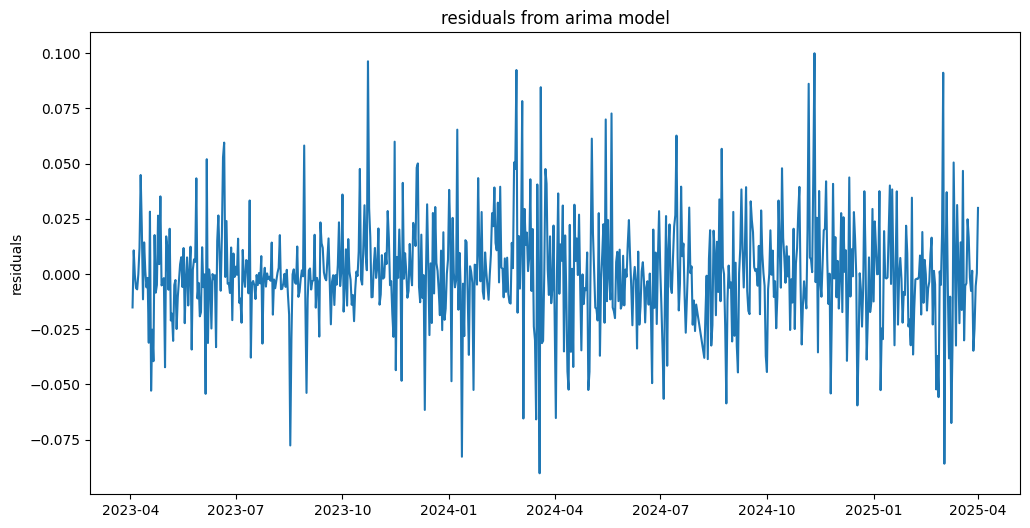

In [48]:
residuals = model.resid()

plt.figure(figsize=(12,6))
plt.plot(residuals)
plt.title('residuals from arima model')
plt.ylabel('residuals')
plt.show()

In [49]:
from statsmodels.stats.diagnostic import acorr_ljungbox

lb_value, lb_pvalue = acorr_ljungbox(residuals, lags=10)
print(f'Ljung-box test p-value: {lb_pvalue}')

Ljung-box test p-value: lb_pvalue


C:\Users\user\AppData\Roaming\Python\Python311\site-packages\arch\univariate\base.py:309: DataScaleWarning: y is poorly scaled, which may affect convergence of the optimizer when
estimating the model parameters. The scale of y is 0.0006018. Parameter
estimation work better when this value is between 1 and 1000. The recommended
rescaling is 100 * y.

This warning can be disabled by either rescaling y before initializing the
model or by setting rescale=False.

  warnings.warn(


Iteration:      1,   Func. Count:      6,   Neg. LLF: 6179893.084794199
Iteration:      2,   Func. Count:     17,   Neg. LLF: 459466.0348033716
Iteration:      3,   Func. Count:     28,   Neg. LLF: 36564.46805341553
Iteration:      4,   Func. Count:     39,   Neg. LLF: -1668.6585109104724
Optimization terminated successfully    (Exit mode 0)
            Current function value: -1668.6585112508913
            Iterations: 8
            Function evaluations: 39
            Gradient evaluations: 4
                     Constant Mean - GARCH Model Results                      
Dep. Variable:                   None   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:                1668.66
Distribution:                  Normal   AIC:                          -3329.32
Method:            Maximum Likelihood   BIC:                          -3310.98
                           

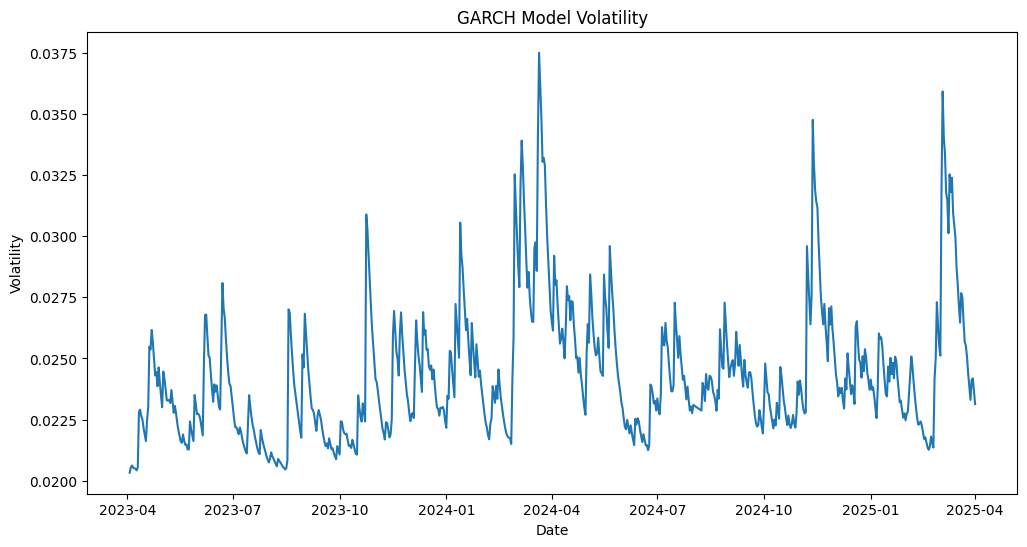

In [50]:
from arch import arch_model

garch_model = arch_model(residuals, vol='Garch', p=1, q=1)
garch_fitted = garch_model.fit()

print(garch_fitted.summary())

plt.figure(figsize=(12, 6))
plt.plot(garch_fitted.conditional_volatility)
plt.title('GARCH Model Volatility')
plt.xlabel('Date')
plt.ylabel('Volatility')
plt.show()

C:\Users\user\AppData\Roaming\Python\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
C:\Users\user\AppData\Roaming\Python\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(
C:\Users\user\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


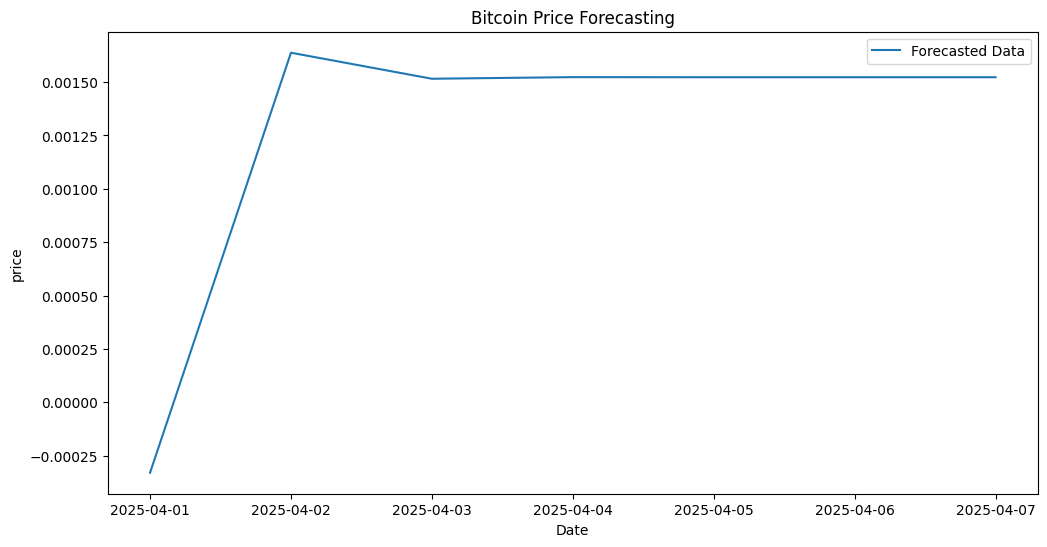

In [55]:
forecast_steps = 7
forecast_df = model.predict(n_periods=forecast_steps)

plt.figure(figsize=(12, 6))
#plt.plot(df.index, df['log_return'], label='Historical Data')
plt.plot(pd.date_range(df.index[-1], periods=forecast_steps, freq='D'), forecast_df, label='Forecasted Data')
plt.title('Bitcoin Price Forecasting')
plt.xlabel('Date')
plt.ylabel('price')
plt.legend()
plt.show()